# Physical Games Project: Soccer Penalty Kicks

## My Question
A soccer player practices penalty kicks in rounds of **10 kicks**. A round is considered a **"great round" if she scores at least 8 goals**.

What is the probability that she has a great round (scores 8 or more goals out of 10)? On average, how many goals should she expect to score per round, and how much does that number typically vary from round to round?

- The probability of scoring on any single penalty kick is p = 0.75 (75%).
- Every kick is independent of the others (a miss or goal does not change the next kick).
- The probability stays the same for all 10 kicks (no fatigue or nerves).

## What Type of Study Is This?
This is a simulation study of a binomial experiment.

## My Simulation
**1. Random variable (X):**
X = the number of goals scored in one round of 10 penalty kicks. X is discrete and can take the whole-number values 0, 1, 2, ..., 10.

**2. One trial and its outcomes:**
One trial = one penalty kick. There are two possible outcomes:
- Success (goal) with probability p = 0.75
- Failure (miss or save) with probability q = 1 − p = 0.25

In the code, each kick is simulated by generating a random number between 0 and 1. If the number is less than 0.75, the kick is a goal. A round is 10 of these kicks, and we simulate 1000 rounds.

## My Analysis
### Step 1: Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)          
rng = np.random.default_rng(42)

n = 10        
p = 0.75     
q = 1 - p
num_sims = 1000   

### Step 2: Simulate 1000 rounds of 10 penalty kicks

In [3]:
kicks = rng.random((num_sims, n)) < p     
X = kicks.sum(axis=1)                    
print("First 20 simulated rounds (goals out of 10):")
print(X[:20])

First 20 simulated rounds (goals out of 10):
[ 5  7  6  9  7  8  9  8  9  9  6  8 10  7  9  7  6  7  7  7]


### Step 3: Histogram of the probability distribution

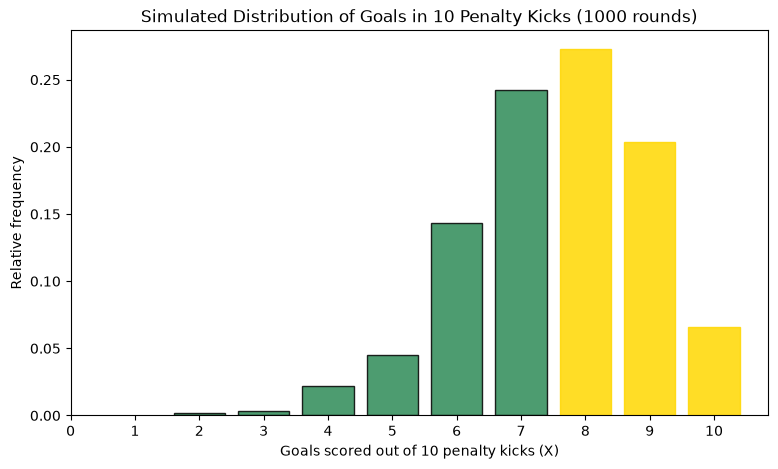

In [4]:
values, counts = np.unique(X, return_counts=True)
rel_freq = counts / num_sims

plt.figure(figsize=(9, 5))
bars = plt.bar(values, rel_freq, color="seagreen", edgecolor="black", alpha=0.85)
for v, b in zip(values, bars):
    if v >= 8:
        b.set_color("gold")
plt.xticks(range(0, n + 1))
plt.xlabel("Goals scored out of 10 penalty kicks (X)")
plt.ylabel("Relative frequency")
plt.title("Simulated Distribution of Goals in 10 Penalty Kicks (1000 rounds)")
plt.show()

### Step 4: Estimate and calculate the probability of a great round

In [5]:
est_prob = np.mean(X >= 8)
print(f"Estimated P(X >= 8) from simulation: {est_prob:.3f}")

theo_prob = sum(stats.binom.pmf(k, n, p) for k in range(8, 11))
print(f"Theoretical P(X >= 8) (binomial):    {theo_prob:.3f}")
print(f"Difference:                           {abs(est_prob - theo_prob):.3f}")

Estimated P(X >= 8) from simulation: 0.543
Theoretical P(X >= 8) (binomial):    0.526
Difference:                           0.017


### Step 5: Mean (expected value) and standard deviation
For a binomial distribution:
- Mean: $\mu = np = 10(0.75) = 7.5$
- Standard deviation: $\sigma = \sqrt{np(1-p)} = \sqrt{10(0.75)(0.25)} \approx 1.369$

In [6]:
# --- Mean and standard deviation ---
sim_mean = X.mean()
sim_sd = X.std()

theo_mean = n * p                   
theo_sd = np.sqrt(n * p * q)         

print(f"Simulated  mean = {sim_mean:.3f},  standard deviation = {sim_sd:.3f}")
print(f"Theoretical mean = {theo_mean:.3f},  standard deviation = {theo_sd:.3f}")

Simulated  mean = 7.558,  standard deviation = 1.411
Theoretical mean = 7.500,  standard deviation = 1.369


### Step 6: Compare simulated vs. theoretical distribution

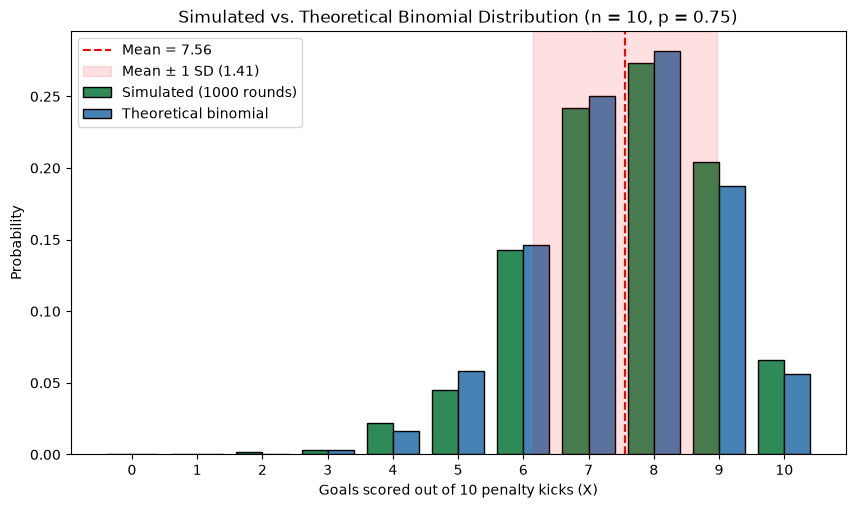

In [7]:
k = np.arange(0, n + 1)
theo_pmf = stats.binom.pmf(k, n, p)
sim_pmf = np.array([np.mean(X == i) for i in k])

width = 0.4
plt.figure(figsize=(10, 5.5))
plt.bar(k - width/2, sim_pmf, width, label="Simulated (1000 rounds)", color="seagreen", edgecolor="black")
plt.bar(k + width/2, theo_pmf, width, label="Theoretical binomial", color="steelblue", edgecolor="black")
plt.axvline(sim_mean, color="red", linestyle="--", label=f"Mean = {sim_mean:.2f}")
plt.axvspan(sim_mean - sim_sd, sim_mean + sim_sd, color="red", alpha=0.12,
            label=f"Mean ± 1 SD ({sim_sd:.2f})")
plt.xticks(k)
plt.xlabel("Goals scored out of 10 penalty kicks (X)")
plt.ylabel("Probability")
plt.title("Simulated vs. Theoretical Binomial Distribution (n = 10, p = 0.75)")
plt.legend()
plt.show()

In [8]:
print(f"{'X':>3} | {'Simulated':>10} | {'Theoretical':>11}")
print("-" * 30)
for i in k:
    print(f"{i:>3} | {sim_pmf[i]:>10.3f} | {theo_pmf[i]:>11.3f}")

  X |  Simulated | Theoretical
------------------------------
  0 |      0.000 |       0.000
  1 |      0.000 |       0.000
  2 |      0.002 |       0.000
  3 |      0.003 |       0.003
  4 |      0.022 |       0.016
  5 |      0.045 |       0.058
  6 |      0.143 |       0.146
  7 |      0.242 |       0.250
  8 |      0.273 |       0.282
  9 |      0.204 |       0.188
 10 |      0.066 |       0.056


## My Conclusion


There is a 52-54% probability that she will be able to score at least 8 out of 10 shots on target (theoretical $P(X \ge 8) \approx 0.526$, simulation $\approx 0.543$). She would be expected to score an average of about 7.5 goals in each round, with the standard deviation being about 1.4 goals**. The graph is negatively skewed, because of the high success rate of 75%, and the majority of the rounds will have a high number of goals, with 7 and 8 being the most frequent ones. Scoring 10/10 will occur in about 6% of the rounds, whereas scoring less than 5 or 6 goals will be uncommon.